Please upload the input image:


Saving sunset.jpg to sunset.jpg


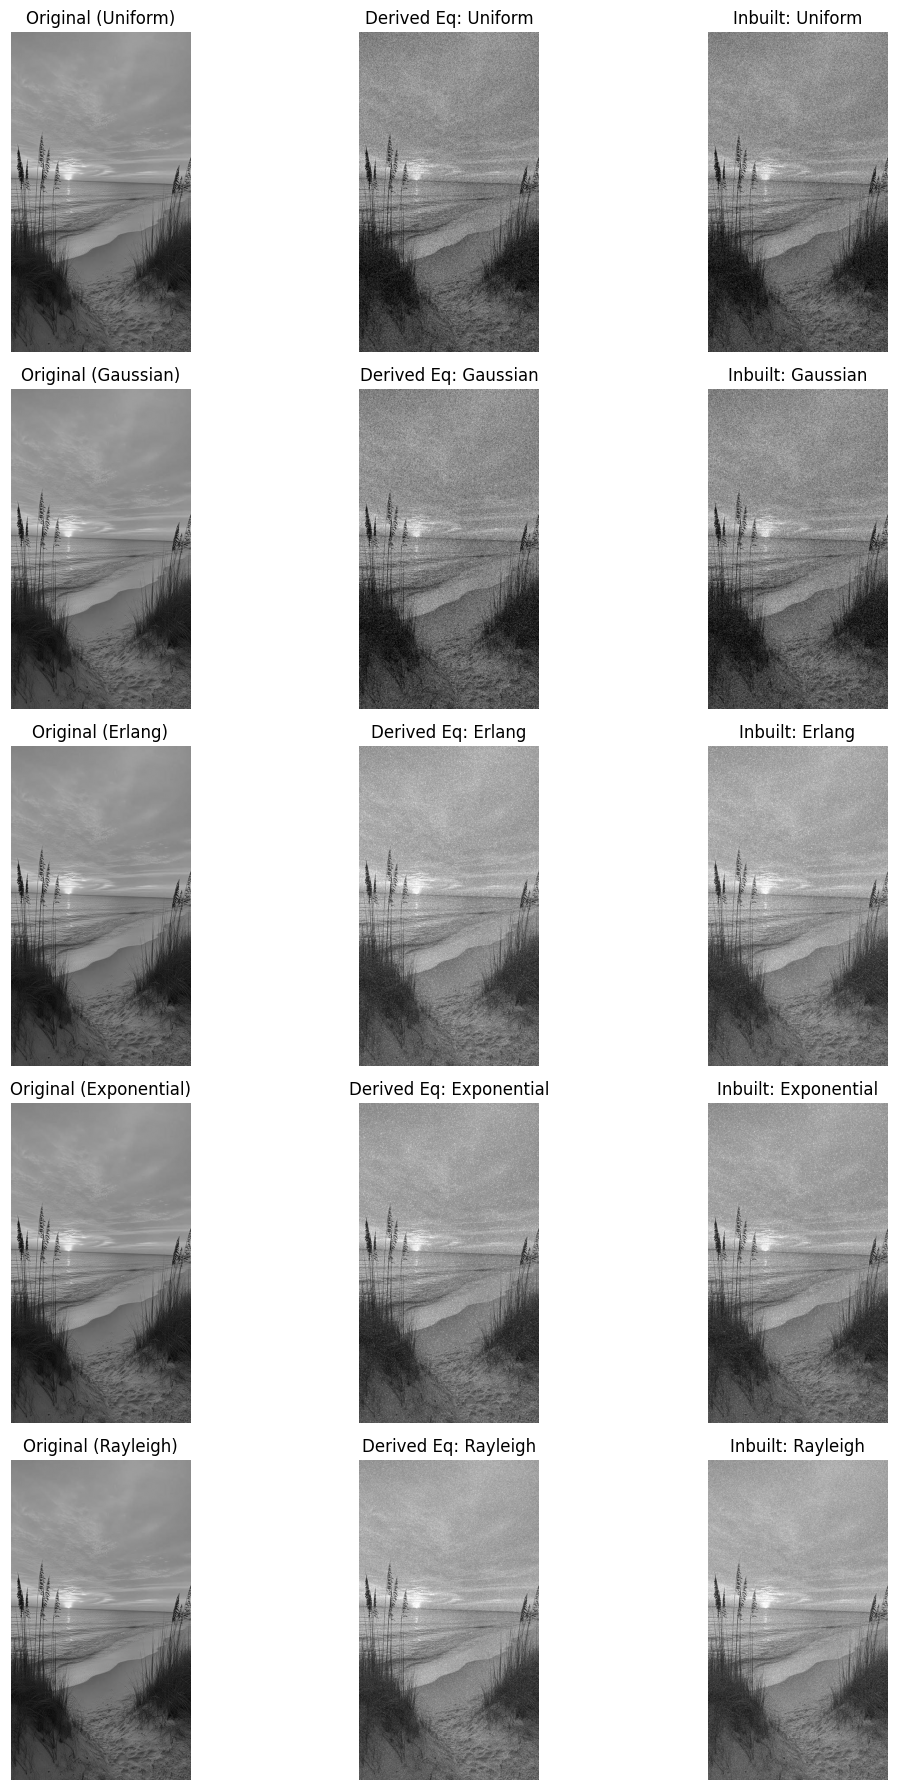

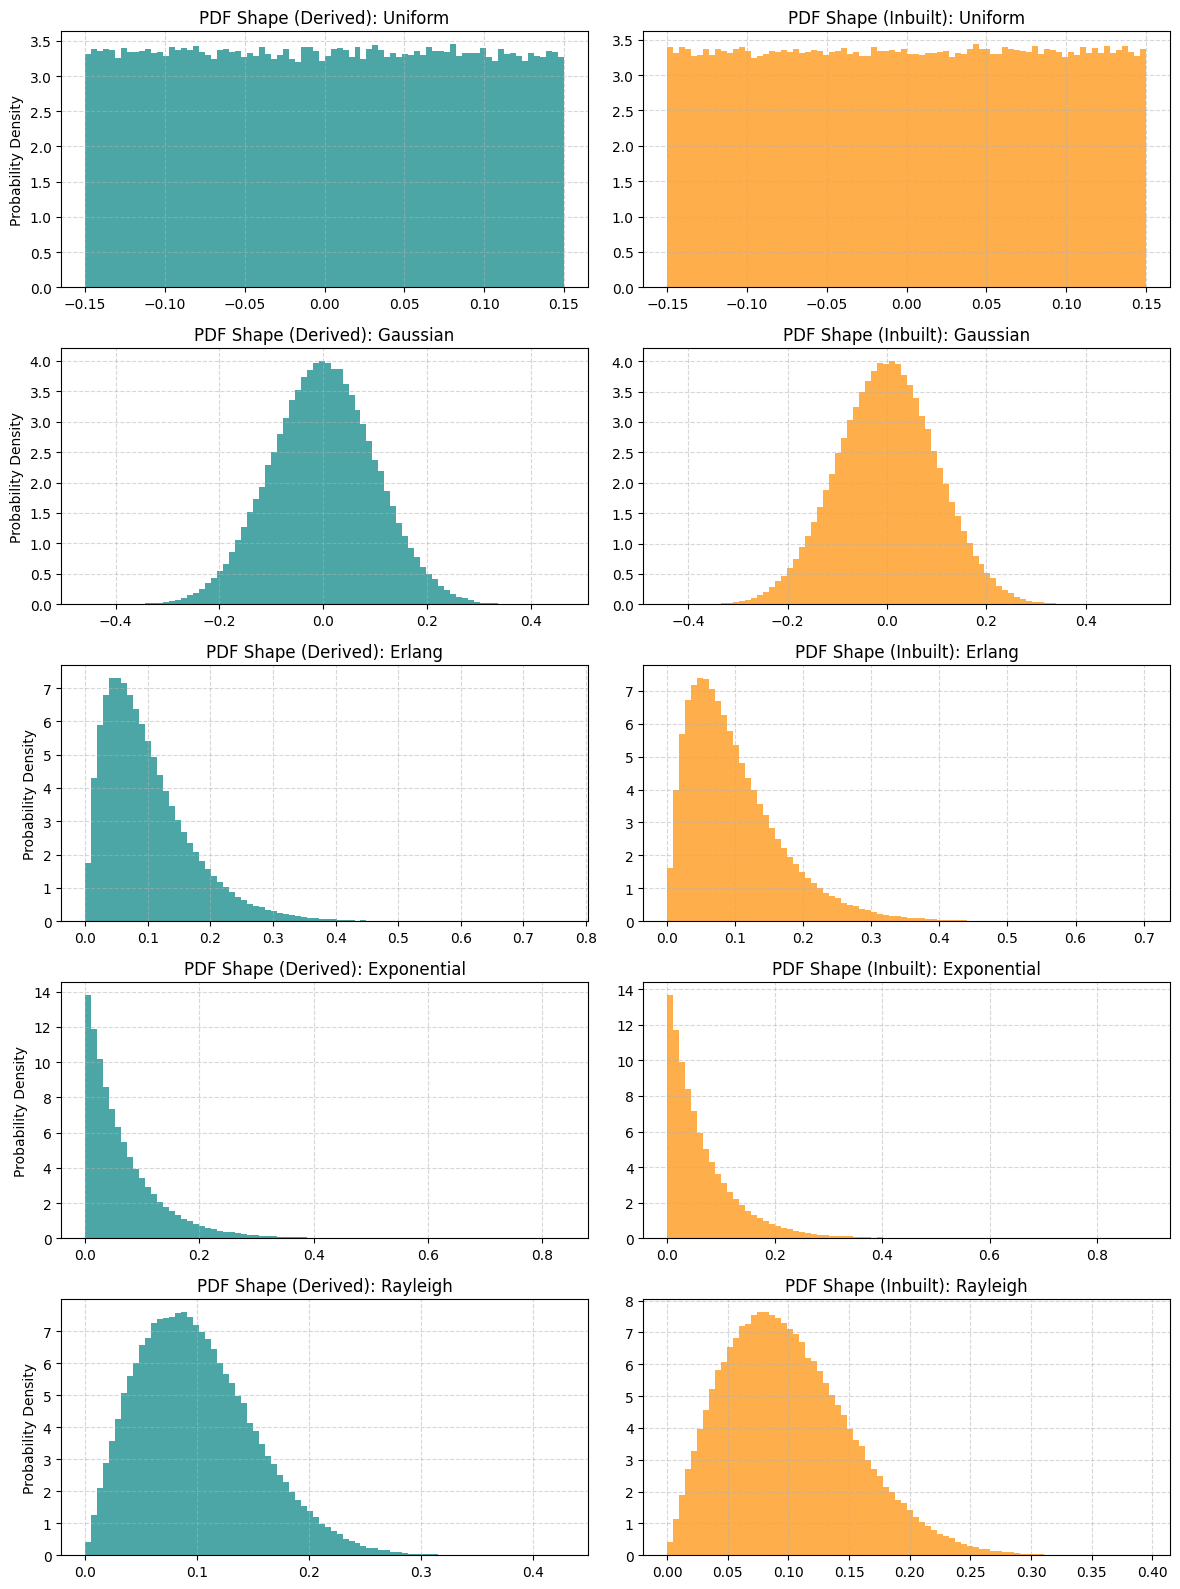

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
from skimage.util import random_noise

print("Please upload the input image:")
uploaded = files.upload()
filename = list(uploaded.keys())[0]

img = cv2.imread(filename, cv2.IMREAD_GRAYSCALE)
img_norm = img.astype(np.float64) / 255.0
shape = img_norm.shape


eps = 1e-10

a, b = -0.15, 0.15
u_uniform = np.random.uniform(0, 1, shape)
noise_uniform = a + (b - a) * u_uniform

u1 = np.clip(np.random.uniform(0, 1, shape), eps, 1.0)
u2 = np.random.uniform(0, 1, shape)
mean_gauss, std_gauss = 0.0, 0.1
noise_gaussian = mean_gauss + std_gauss * (np.sqrt(-2.0 * np.log(u1)) * np.cos(2.0 * np.pi * u2))


k_erlang = 2
theta_erlang = 0.05
noise_erlang = np.zeros(shape)
for _ in range(k_erlang):
    u_k = np.clip(np.random.uniform(0, 1, shape), eps, 1.0)
    noise_erlang += -theta_erlang * np.log(u_k)

lambda_exp = 15.0
u_exp = np.clip(np.random.uniform(0, 1, shape), 0.0, 1.0 - eps)
noise_exponential = -(1.0 / lambda_exp) * np.log(1.0 - u_exp)

a_ray, b_ray = 0.0, 0.08
u_ray = np.clip(np.random.uniform(0, 1, shape), 0.0, 1.0 - eps)
noise_rayleigh = a_ray + b_ray * np.sqrt(-2.0 * np.log(1.0 - u_ray))

derived_noises = [
    ("Uniform", noise_uniform),
    ("Gaussian", noise_gaussian),
    ("Erlang", noise_erlang),
    ("Exponential", noise_exponential),
    ("Rayleigh", noise_rayleigh)
]


inbuilt_noises = [
    ("Uniform", np.random.uniform(a, b, shape)),
    ("Gaussian", random_noise(img_norm, mode='gaussian', mean=mean_gauss, var=std_gauss**2, clip=False) - img_norm),
    ("Erlang", np.random.gamma(shape=k_erlang, scale=theta_erlang, size=shape)),
    ("Exponential", np.random.exponential(scale=1.0 / lambda_exp, size=shape)),
    ("Rayleigh", np.random.rayleigh(scale=b_ray, size=shape))
]


fig, axes = plt.subplots(5, 3, figsize=(12, 18))

for idx in range(5):
    name, n_derived = derived_noises[idx]
    _, n_inbuilt = inbuilt_noises[idx]

    noisy_derived = np.clip(img_norm + n_derived, 0, 1)
    noisy_inbuilt = np.clip(img_norm + n_inbuilt, 0, 1)

    axes[idx, 0].imshow(img_norm, cmap='gray')
    axes[idx, 0].set_title(f"Original ({name})")
    axes[idx, 0].axis('off')

    axes[idx, 1].imshow(noisy_derived, cmap='gray')
    axes[idx, 1].set_title(f"Derived Eq: {name}")
    axes[idx, 1].axis('off')

    axes[idx, 2].imshow(noisy_inbuilt, cmap='gray')
    axes[idx, 2].set_title(f"Inbuilt: {name}")
    axes[idx, 2].axis('off')

plt.tight_layout()
plt.show()


fig, axes = plt.subplots(5, 2, figsize=(12, 16))

for idx in range(5):
    name, n_derived = derived_noises[idx]
    _, n_inbuilt = inbuilt_noises[idx]

    axes[idx, 0].hist(n_derived.ravel(), bins=80, density=True, color='teal', alpha=0.7)
    axes[idx, 0].set_title(f"PDF Shape (Derived): {name}")
    axes[idx, 0].set_ylabel("Probability Density")
    axes[idx, 0].grid(True, linestyle='--', alpha=0.5)

    axes[idx, 1].hist(n_inbuilt.ravel(), bins=80, density=True, color='darkorange', alpha=0.7)
    axes[idx, 1].set_title(f"PDF Shape (Inbuilt): {name}")
    axes[idx, 1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()